# Milestone 2 — Exploratory Data Analysis (embedded figures)

**Project:** Evaluating Graph Encoding Methods for LLM Reasoning on Social Networks  
**Team:** Ozan Polat, Baris Surmelioglu  
**Deadline:** 9 November 2026

We analyze two Stanford SNAP datasets (Facebook friendship; directed Email-Eu-core communication) plus three synthetic network families. This is **EDA only**; it does **not** measure LLM accuracy.

## 1. Setup, source links and download

- [SNAP ego-Facebook](https://snap.stanford.edu/data/ego-Facebook.html)
- [SNAP Email-Eu-core](https://snap.stanford.edu/data/email-Eu-core.html)
- [Talk Like a Graph (ICLR 2024)](https://arxiv.org/abs/2310.04560)

On your Windows computer, install packages with `pip install -r requirements.txt`. The next cell downloads datasets if they are missing. **Keep `MODE='real'` for submission.** Use `'demo'` strictly for offline code tests, not for reporting Facebook/email results.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

ROOT = Path.cwd()
if not (ROOT / 'run_m2.py').exists() and (ROOT.parent / 'run_m2.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from swsn_m2.pipeline import (load_real_graphs, generate_synthetic_graphs, graphs_demo,
                              analyze_graph, sample_connected_subgraph, three_encodings)
from io import BytesIO
from IPython.display import Image as NotebookImage, display

def show_figure(fig=None):
    """Embed the figure into the notebook even when Matplotlib uses the Agg backend."""
    if fig is None:
        fig = plt.gcf()
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=135, bbox_inches="tight")
    display(NotebookImage(data=buffer.getvalue()))
    plt.close(fig)

MODE = 'real'  # Change to 'demo' only to check the notebook offline.
if MODE == 'real':
    graphs = {**load_real_graphs(ROOT), **generate_synthetic_graphs()}
else:
    graphs = graphs_demo()
print('Loaded networks:', ', '.join(graphs))

[DATA CHECK] Facebook: 4039 nodes, 88234 edges, 0 self-loops preserved in raw EDA


[DATA CHECK] Email-Eu-core: 1005 nodes, 25571 edges, 642 self-loops preserved in raw EDA


Loaded networks: Facebook (SNAP), Email-Eu-core (SNAP), ER synthetic (n=300), BA synthetic (n=300), SBM synthetic (n=300)


## 2. Structural overview

In a **directed** network, edges (u,v) and (v,u) are different relationships. We therefore preserve email direction in data loading. Density denominators also differ by graph type. A *weak* component ignores direction while a *strong* component requires mutual directed reachability.

**M2 data-integrity note:** The directed Email-Eu-core raw graph includes 642 self-loops. We preserve them here to match the published 25,571 directed edges. For graph-to-text LLM question samples, the pipeline removes self-loops. Directed total degree is in-degree plus out-degree; density here uses raw edges including self-loops.

In [2]:
rows = [analyze_graph(g, name) for name,g in graphs.items()]
metrics = pd.DataFrame(rows)
display(metrics[['dataset','type','nodes','edges','mean_total_degree','density',
                 'weak_or_connected_components','strong_components',
                 'approx_clustering_undirected_projection']].round(4))

,dataset,type,nodes,edges,mean_total_degree,density,weak_or_connected_components,strong_components,approx_clustering_undirected_projection
0,Facebook (SNAP),undirected,4039,88234,43.6910,0.0108,1,NaN,0.6267
1,Email-Eu-core (SNAP),directed,1005,25571,50.8876,0.0253,20,203.0,0.3970
2,ER synthetic (n=300),undirected,300,1613,10.7533,0.0360,1,NaN,0.0304
3,BA synthetic (n=300),undirected,300,891,5.9400,0.0199,1,NaN,0.0549
4,SBM synthetic (n=300),undirected,300,2290,15.2667,0.0511,1,NaN,0.0976


## 3. Graph sizes and density

Compare average degree and density separately because their scales differ. The email network's total degree counts both incoming and outgoing communications.

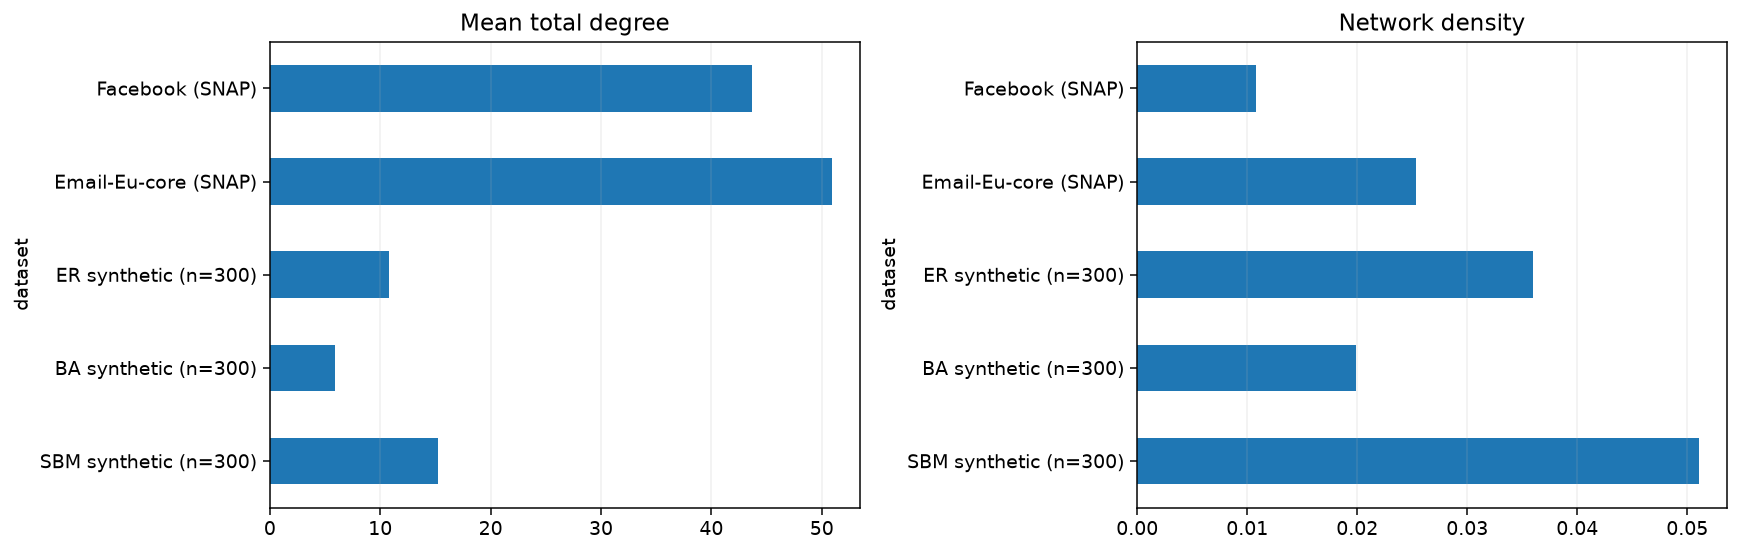

In [3]:
fig, axes = plt.subplots(1,2,figsize=(13,4.2))
metrics.plot.barh(x='dataset', y='mean_total_degree', ax=axes[0], legend=False)
metrics.plot.barh(x='dataset', y='density', ax=axes[1], legend=False)
axes[0].set_title('Mean total degree');axes[1].set_title('Network density')
for ax in axes: ax.invert_yaxis();ax.grid(axis='x', alpha=.2)
fig.tight_layout();show_figure()

## 4. Degree distributions

A complementary cumulative distribution (CCDF) expresses the fraction of nodes with degree **at least k**. Log-log scale makes tail differences easier to see. This is not a fitted power-law test.

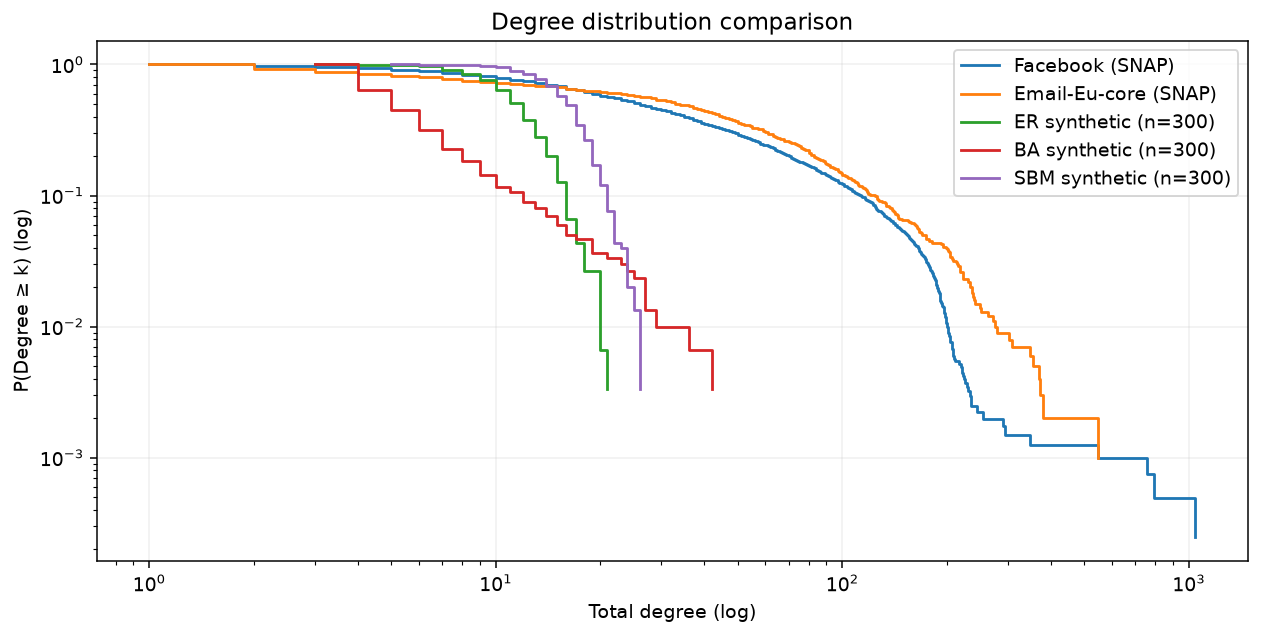

In [4]:
fig,ax=plt.subplots(figsize=(11,5))
for name,g in graphs.items():
    degrees=np.array([d for _,d in g.degree()],dtype=float)
    k=np.unique(degrees[degrees>0])
    p=[(degrees>=v).mean() for v in k]
    ax.step(k,p,where='post',label=name)
ax.set_xscale('log');ax.set_yscale('log')
ax.set_xlabel('Total degree (log)');ax.set_ylabel('P(Degree ≥ k) (log)')
ax.set_title('Degree distribution comparison');ax.grid(alpha=.2);ax.legend();show_figure()

**Interpretation:** On the observed CCDF, real SNAP graphs display broad total-degree tails relative to these 300-node synthetic baselines. This is a descriptive comparison, not a controlled comparison at identical graph sizes. The email network contains 20 weak components and 203 strong components; Facebook has a single connected component. Local subgraph sampling also changes the observed degree distribution.

## 4b. Department-based communication analysis (Email-Eu-core only)

We examine the distribution of the 42 anonymized department labels and count what fraction of emails connect people in the same department. This is a dataset-specific analysis instead of relying only on generic graph statistics.

Anonymized departments: 42
Within-department directed ties: 9287 / 25571 = 36.3 %


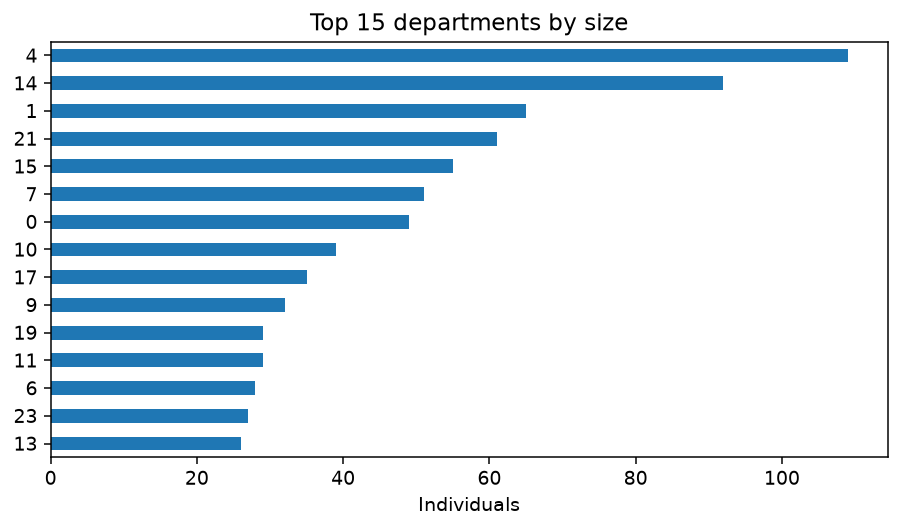

In [5]:
email_graph=graphs.get('Email-Eu-core (SNAP)')
if email_graph is not None:
    labels=nx.get_node_attributes(email_graph,'department')
    department_sizes=pd.Series(list(labels.values())).value_counts().sort_values(ascending=False)
    within=sum(labels.get(u)==labels.get(v) for u,v in email_graph.edges() if u in labels and v in labels)
    print('Anonymized departments:',len(department_sizes))
    print('Within-department directed ties:',within,'/',email_graph.number_of_edges(),
          '=',round(within/email_graph.number_of_edges()*100,1),'%')
    department_sizes.head(15).sort_values().plot.barh(figsize=(8,4),title='Top 15 departments by size')
    plt.xlabel('Individuals');show_figure()
else:
    print('Department analysis requires real Email-Eu-core; this is offline demo mode.')

## 5. Induced network samples

LLM prompts cannot contain the entire Facebook network. We sample **bounded-size induced subgraphs**, preserving the actual direction of each relation. These samples emphasize local neighborhoods; our future evaluation must acknowledge that sampling bias.

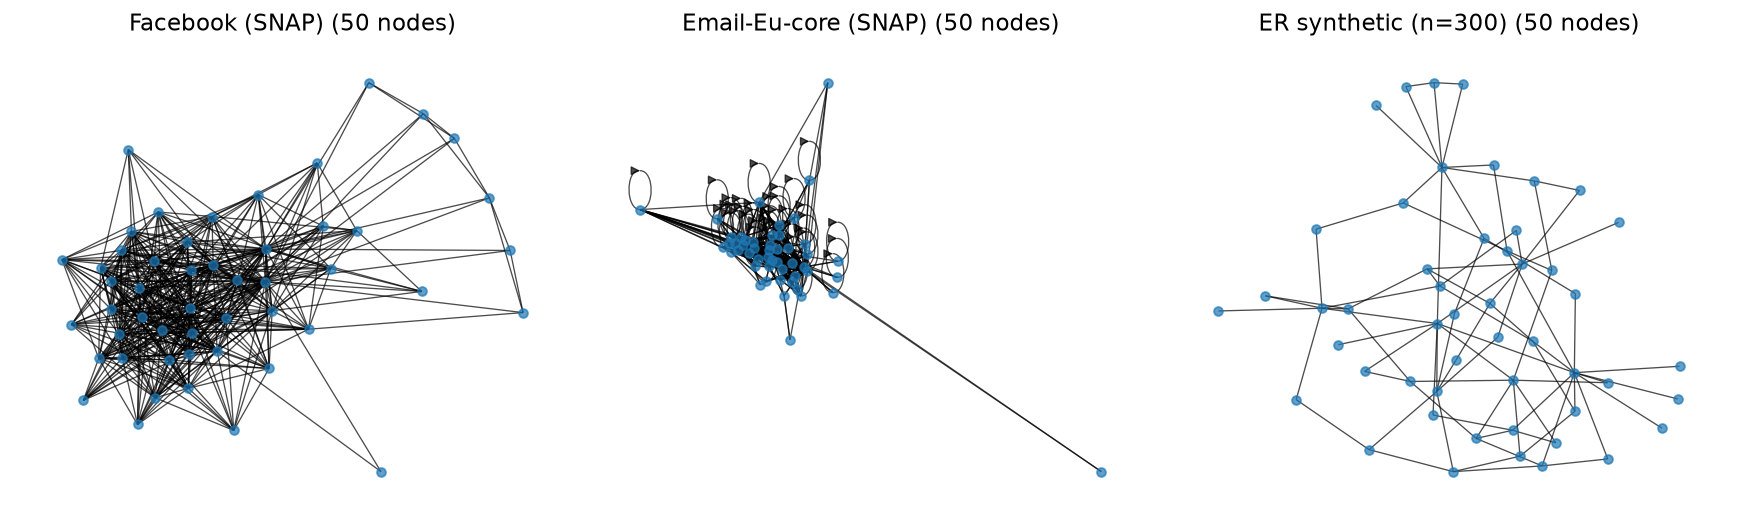

In [6]:
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,(name,g) in zip(axs,list(graphs.items())[:3]):
    sub=sample_connected_subgraph(g,min(50,len(g)),2026)
    nx.draw(sub,pos=nx.spring_layout(sub,seed=2026),ax=ax,node_size=22,width=.7,alpha=.7,
            with_labels=False,arrows=False)
    ax.set_title(f'{name} ({len(sub)} nodes)');ax.axis('off')
plt.tight_layout();show_figure()

## 6. Downstream graph-to-text encoding examples (future milestone)

For each same induced graph we can make an edge list, adjacency list, or natural-language encoding. **This code does not call an LLM**: we are only preparing comparable question inputs and reference answers.

In [7]:
sample_name = list(graphs)[0]
sample = sample_connected_subgraph(graphs[sample_name], 12, 2026)
encodings = three_encodings(sample)
for name,text in encodings.items():
    print(f'\n{name}:\n{text[:600]}')
print('NetworkX reference for first node:',dict(sample.degree())[next(iter(sample.nodes()))])


edge_list:
Graph is undirected. Edges: (366, 606); (366, 1001); (366, 1155); (366, 1358); (366, 1397); (366, 1740); (366, 1844); (606, 1001); (606, 1358); (606, 1487); (606, 1536); (1001, 1155); (1001, 1207); (1001, 1358); (1001, 1397); (1001, 1422); (1001, 1487); (1001, 1536); (1001, 1740); (1001, 1844); (1155, 1358); (1155, 1487); (1155, 1844); (1358, 1397); (1358, 1740); (1358, 1844); (1397, 1487); (1397, 1536); (1397, 1844); (1422, 1487); (1487, 1536); (1487, 1844)

adjacency_list:
Graph is undirected. Outgoing neighbors (directed), or neighbors (undirected):
366: [606, 1001, 1155, 1358, 1397, 1740, 1844]
606: [366, 1001, 1358, 1487, 1536]
1001: [366, 606, 1155, 1207, 1358, 1397, 1422, 1487, 1536, 1740, 1844]
1155: [366, 1001, 1358, 1487, 1844]
1207: [1001]
1358: [366, 606, 1001, 1155, 1397, 1740, 1844]
1397: [366, 1001, 1358, 1487, 1536, 1844]
1422: [1001, 1487]
1487: [606, 1001, 1155, 1397, 1422, 1536, 1844]
1536: [606, 1001, 1397, 1487]
1740: [366, 1001, 1358]
1844: [366, 1001,

## 7. Interpretation and limitations

**Questions we can answer at M2:** How do real and generated graph sizes, degree distributions, densities and connectivity differ? Why must email edges be treated as directed? Which bounded-size subgraph sampling is practical for an LLM?

**Not yet claimed:** improved LLM performance, real token counts, model latency, or new algorithmic contributions.

**Limitations:** Ego-Facebook is a merged ego network (not all Facebook users), Email-Eu-core is a single institution (not an entire European network), and random local sampling is not representative of every global property. The clustering field in this notebook is a fixed-seed vertex-sampled estimate computed on undirected projections.

In [8]:
# Data integrity checks for REAL mode; no fabricated output in this notebook.
if MODE == 'real':
    assert graphs['Facebook (SNAP)'].number_of_nodes() == 4039
    assert graphs['Email-Eu-core (SNAP)'].number_of_edges() == 25571
    assert nx.number_of_selfloops(graphs['Email-Eu-core (SNAP)']) == 642
    print('Real SNAP counts and email self-loops verified.')
else:
    print('Demo mode: real-data integrity checks skipped.')

Real SNAP counts and email self-loops verified.


In [9]:
# One-command pipeline also saves reproducible outputs and creates the 2-page PDF.
# Run this cell on your computer when network access is available:
# import subprocess
# subprocess.run([sys.executable, str(ROOT / 'run_m2.py')], check=True)

print('Notebook EDA complete. Use python run_m2.py to write output files and final 2-page PDF.')

Notebook EDA complete. Use python run_m2.py to write output files and final 2-page PDF.
